# EV Battery Failure Prediction — Exploratory Data Analysis and Modeling

This notebook explores an EV battery failure dataset, prepares numerical and categorical
features, compares classification models, and evaluates the selected model on a held-out
test set.

## Notebook workflow

1. Load and inspect the dataset.
2. Examine missing values, target relationships, and potentially engineered features.
3. Split the data and build preprocessing pipelines.
4. Visualize important patterns in the dataset.
5. Train Logistic Regression, Random Forest, and Extra Trees classifiers.
6. Select a decision threshold using validation data and report final test metrics.

**Target:** `battery_failure` (assumed to be encoded as `0 = No Failure` and `1 = Failure`
where those labels are used in plots and reports).

> Run the notebook from top to bottom. The CSV file should be named with the
> `ev_battery_failure` prefix and be located in the notebook's working directory or
> one of its subdirectories. The notebook does not include the dataset itself.

## Part 1 — Exploratory data analysis and preprocessing

This section loads the data and investigates its structure and quality before modeling.

### 1. Import libraries

Import the data-handling, visualization, and scikit-learn preprocessing utilities used throughout the EDA and preprocessing workflow.

In [1]:
# EV Battery Failure Dataset - Corrected EDA and Preprocessing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --------------------------------------------------

### 2. Load the dataset

Search recursively from the current working directory for a matching CSV file, load the first match, and preview representative rows.

In [2]:
# 1. Load dataset
# --------------------------------------------------

# Search the current Jupyter folder and its subfolders
files = list(Path.cwd().rglob("ev_battery_failure*.csv"))

if not files:
    raise FileNotFoundError(
        "CSV not found. Put ev_battery_failure_dataset.csv "
        "inside the Jupyter working folder or update the file path."
    )

file_path = files[0]
print("Dataset path:", file_path)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
display(df.head())
display(df.tail())
display(df.sample(min(5, len(df)), random_state=42))
df.shape

# --------------------------------------------------

Dataset path: D:\machine_learning_projects\New folder\ev_battery_failure_dataset.csv
Dataset loaded successfully!


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Nissan,Leaf,SUV,2019.0,CATL,LMO,82.54,RWD,98163.0,...,2.0,3.0,0.0,0.0,53.5,66.0,65.2,0.0,401.0,0
1,EV100001,Audi,e-tron,Sedan,2018.0,Samsung SDI,NaN,64.17,AWD,113600.0,...,0.0,3.0,0.0,51.0,38.8,67.8,46.3,40.9,1094.0,0
2,EV100002,Toyota,bZ4X,Van,2018.0,Guoxuan,NMC,90.92,RWD,242253.0,...,4.0,1.0,0.0,36.2,66.1,48.6,0.0,6.5,645.0,0
3,EV100003,Volkswagen,ID.3,Hatchback,2022.0,CATL,NMC,47.35,AWD,83700.0,...,0.0,3.0,1.0,23.4,32.5,58.2,NaN,NaN,867.0,0
4,EV100004,Tesla,Model X,Crossover,2015.0,BYD Battery,NMC,68.04,FWD,88784.0,...,3.0,2.0,1.0,51.2,45.4,51.0,NaN,100.0,1090.0,0


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
199995,EV299995,BYD,Song Plus,Hatchback,2016.0,CATL,LFP,45.99,FWD,182311.0,...,3.0,1.0,1.0,62.3,NaN,78.6,0.0,51.5,2691.0,0
199996,EV299996,Lucid,Air,Crossover,2015.0,LG Energy Solution,NMC,67.65,AWD,275317.0,...,2.0,5.0,2.0,33.1,89.5,59.3,73.7,57.0,420.0,0
199997,EV299997,BYD,Song Plus,SUV,NaN,BYD Battery,LFP,98.08,FWD,158747.0,...,2.0,2.0,0.0,79.0,13.1,64.7,32.8,7.6,3148.0,0
199998,EV299998,Tesla,Model Y,Hatchback,2016.0,SK On,NMC,51.49,FWD,95122.0,...,2.0,2.0,0.0,24.3,59.5,50.6,69.4,12.7,797.0,0
199999,EV299999,Tesla,Model 3,SUV,2024.0,CATL,NCA,88.39,RWD,54982.0,...,0.0,1.0,1.0,47.7,16.6,49.6,32.0,70.8,925.0,0


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
119737,EV219737,Tesla,Model 3,SUV,2015.0,Samsung SDI,NMC,95.33,FWD,231842.0,...,3.0,2.0,0.0,94.4,88.9,52.4,52.0,78.1,690.0,1
72272,EV172272,Nissan,Leaf,Crossover,2016.0,Panasonic,NMC,83.07,FWD,233321.0,...,4.0,4.0,0.0,23.8,70.5,58.1,85.1,34.9,703.0,0
158154,EV258154,Ford,Mustang Mach-E,Sedan,2018.0,CATL,LFP,83.88,FWD,219348.0,...,2.0,0.0,0.0,12.1,11.9,NaN,100.0,2.8,3634.0,0
65426,EV165426,Tesla,Model Y,Crossover,2017.0,LG Energy Solution,NaN,71.12,AWD,50838.0,...,1.0,NaN,1.0,NaN,39.5,53.6,56.1,20.5,NaN,0
30074,EV130074,Ford,Mustang Mach-E,SUV,2016.0,CATL,LFP,77.77,RWD,151584.0,...,4.0,2.0,3.0,3.5,30.9,83.8,57.7,20.5,3477.0,0


(200000, 70)

### 3. Inspect dataset structure

Review column names, dimensions, descriptive statistics, data types, and missing-value counts. This establishes the dataset's basic quality and schema.

In [3]:
# 2. Basic dataset inspection
# --------------------------------------------------

print("Columns:")
print(df.columns.tolist())

print("\nShape:", df.shape)

display(df.describe(include="all").T)

df.info()

print("\nMissing values:")
display(df.isnull().sum())

# Missing count and percentage
mis = pd.DataFrame({
    "count": df.isnull().sum(),
    "percent": df.isnull().mean() * 100
})
display(mis.sort_values("count", ascending=False))

# --------------------------------------------------

Columns:
['vehicle_id', 'vehicle_brand', 'vehicle_model', 'vehicle_type', 'manufacturing_year', 'battery_manufacturer', 'battery_chemistry', 'battery_capacity_kwh', 'drive_type', 'odometer_km', 'vehicle_age_years', 'fleet_or_private', 'battery_serial', 'cycle_count', 'battery_health_percent', 'state_of_charge', 'depth_of_discharge', 'state_of_health', 'cell_voltage_avg', 'cell_voltage_std', 'pack_voltage', 'cell_temperature_avg', 'cell_temperature_max', 'internal_resistance', 'charge_efficiency', 'discharge_efficiency', 'remaining_capacity', 'capacity_loss_percent', 'charging_cycles_last_month', 'fast_charge_ratio', 'slow_charge_ratio', 'average_charge_power_kw', 'average_charging_time', 'overnight_charging_ratio', 'home_charging_ratio', 'charging_interruptions', 'overcharge_events', 'average_speed', 'average_trip_distance', 'aggressive_acceleration_score', 'hard_braking_score', 'regenerative_braking_usage', 'highway_driving_ratio', 'city_driving_ratio', 'daily_distance', 'average_ambi

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
vehicle_id,200000,200000,EV100000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_brand,193564,20,Tesla,21840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_model,191796,55,Model X,5527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_type,193568,6,SUV,58202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
manufacturing_year,190171.0,NaN,NaN,NaN,2019.501333,2.873497,2015.0,2017.0,2020.0,2022.0,2024.0
...,...,...,...,...,...,...,...,...,...,...,...
thermal_health_score,193671.0,NaN,NaN,NaN,63.538378,13.76434,18.0,53.9,61.4,74.0,100.0
charging_quality_score,192814.0,NaN,NaN,NaN,50.989061,27.815242,0.0,30.6,53.5,72.8,100.0
driving_stress_score,193190.0,NaN,NaN,NaN,40.948318,29.848473,0.0,15.5,38.9,63.0,100.0
predicted_remaining_life_cycles,191026.0,NaN,NaN,NaN,1859.485986,1834.356925,0.0,891.0,1245.0,3085.0,15474.0


<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 70 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   vehicle_id                       200000 non-null  str    
 1   vehicle_brand                    193564 non-null  str    
 2   vehicle_model                    191796 non-null  str    
 3   vehicle_type                     193568 non-null  str    
 4   manufacturing_year               190171 non-null  float64
 5   battery_manufacturer             193812 non-null  str    
 6   battery_chemistry                192786 non-null  str    
 7   battery_capacity_kwh             193097 non-null  float64
 8   drive_type                       192732 non-null  str    
 9   odometer_km                      191334 non-null  float64
 10  vehicle_age_years                192317 non-null  float64
 11  fleet_or_private                 191050 non-null  str    
 12  battery_seria

vehicle_id                            0
vehicle_brand                      6436
vehicle_model                      8204
vehicle_type                       6432
manufacturing_year                 9829
                                   ... 
thermal_health_score               6329
charging_quality_score             7186
driving_stress_score               6810
predicted_remaining_life_cycles    8974
battery_failure                       0
Length: 70, dtype: int64

,count,percent
fast_charge_ratio,9879,4.9395
average_speed,9849,4.9245
manufacturing_year,9829,4.9145
home_charging_ratio,9805,4.9025
sensor_fault_count,9674,4.8370
...,...,...
remaining_capacity,6148,3.0740
dust_exposure,6098,3.0490
vehicle_id,0,0.0000
battery_serial,0,0.0000


### 4. Identify feature types

Separate numerical and categorical columns while excluding the target and known identifier fields from the feature lists.

In [4]:
# 3. Identify numerical and categorical columns

target = "battery_failure"

if target not in df.columns:
    raise KeyError(f"Target column '{target}' is missing from the dataset.")

# Identify the two identifier columns
ids = [
    c for c in ["vehicle_id", "battery_serial"]
    if c in df.columns
]

# Identify numerical and categorical columns
num = df.select_dtypes(include=["number"]).columns.tolist()

cat = df.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

# Exclude target and identifiers from feature lists
num = [c for c in num if c != target and c not in ids]
cat = [c for c in cat if c != target and c not in ids]

print("Identifier columns excluded:", ids)
print("Numerical features:", len(num))
print("Categorical features:", len(cat))
print("Total predictor columns:", len(num) + len(cat))

print("\nNumerical columns:")
print(num)

print("\nCategorical columns:")
print(cat)

Identifier columns excluded: ['vehicle_id', 'battery_serial']
Numerical features: 59
Categorical features: 8
Total predictor columns: 67

Numerical columns:
['manufacturing_year', 'battery_capacity_kwh', 'odometer_km', 'vehicle_age_years', 'cycle_count', 'battery_health_percent', 'state_of_charge', 'depth_of_discharge', 'state_of_health', 'cell_voltage_avg', 'cell_voltage_std', 'pack_voltage', 'cell_temperature_avg', 'cell_temperature_max', 'internal_resistance', 'charge_efficiency', 'discharge_efficiency', 'remaining_capacity', 'capacity_loss_percent', 'charging_cycles_last_month', 'fast_charge_ratio', 'slow_charge_ratio', 'average_charge_power_kw', 'average_charging_time', 'overnight_charging_ratio', 'home_charging_ratio', 'charging_interruptions', 'overcharge_events', 'average_speed', 'average_trip_distance', 'aggressive_acceleration_score', 'hard_braking_score', 'regenerative_braking_usage', 'highway_driving_ratio', 'city_driving_ratio', 'daily_distance', 'average_ambient_temperatu

### 5. Examine missingness

Measure missing values in numerical and categorical columns, including missingness rates within each target class.

In [5]:
# 4. Missing values in numerical and categorical columns
# --------------------------------------------------

num_mis = df[num].isnull().sum()
num_mis = num_mis[num_mis > 0].sort_values(ascending=False)
print("Numerical missing values:")
display(num_mis)

cat_mis = df[cat].isnull().sum()
cat_mis = cat_mis[cat_mis > 0].sort_values(ascending=False)
print("Categorical missing values:")
display(cat_mis)

# Missing values by target class
num_mis_target = (
    df.groupby(target)[num]
      .apply(lambda x: x.isnull().mean() * 100)
      .T
)

if 0 in num_mis_target.columns and 1 in num_mis_target.columns:
    num_mis_target.columns = ["No_Failure_0", "Failure_1"]
    num_mis_target["Difference"] = (
        num_mis_target["Failure_1"] - num_mis_target["No_Failure_0"]
    )
    display(num_mis_target.sort_values("Difference", ascending=False))
else:
    print("Target classes are not exactly 0 and 1; showing class-wise missing rates.")
    display(num_mis_target)

cat_mis_target = (
    df.groupby(target)[cat]
      .apply(lambda x: x.isnull().mean() * 100)
      .T
)

if 0 in cat_mis_target.columns and 1 in cat_mis_target.columns:
    cat_mis_target.columns = ["No_Failure_0", "Failure_1"]
    cat_mis_target["Difference"] = (
        cat_mis_target["Failure_1"] - cat_mis_target["No_Failure_0"]
    )
    display(cat_mis_target.sort_values("Difference", ascending=False))
else:
    print("Target classes are not exactly 0 and 1; showing class-wise missing rates.")
    display(cat_mis_target)

# --------------------------------------------------

Numerical missing values:


fast_charge_ratio                  9879
average_speed                      9849
manufacturing_year                 9829
home_charging_ratio                9805
sensor_fault_count                 9674
charging_interruptions             9648
state_of_charge                    9636
state_of_health                    9565
capacity_loss_percent              9559
slow_charge_ratio                  9483
cell_temperature_max               9450
cooling_system_health              9408
cell_voltage_avg                   9398
charge_efficiency                  9305
hard_braking_score                 9239
average_ambient_temperature        9161
regenerative_braking_usage         9069
BMS_warning_count                  9052
average_charge_power_kw            9050
battery_health_percent             8982
predicted_remaining_life_cycles    8974
odometer_km                        8666
daily_distance                     8568
cell_voltage_std                   8563
maintenance_score                  8446


Categorical missing values:


fleet_or_private        8950
vehicle_model           8204
drive_type              7268
battery_chemistry       7214
terrain_type            7127
vehicle_brand           6436
vehicle_type            6432
battery_manufacturer    6188
dtype: int64

,No_Failure_0,Failure_1,Difference
maximum_temperature,4.083208,4.347171,0.263963
cycle_count,3.801665,4.045982,0.244317
cell_temperature_max,4.702381,4.929471,0.227091
abnormal_voltage_events,3.778342,3.995783,0.217442
vehicle_age_years,3.819990,4.035942,0.215952
temperature_variance,3.158058,3.353245,0.195187
state_of_health,4.764576,4.944531,0.179955
cell_temperature_avg,3.824988,3.990764,0.165776
charging_quality_score,3.576764,3.739772,0.163009
sensor_fault_count,4.821217,4.979670,0.158452


,No_Failure_0,Failure_1,Difference
battery_chemistry,3.586204,3.794990,0.208786
battery_manufacturer,3.080315,3.217710,0.137395
drive_type,3.625076,3.714673,0.089597
fleet_or_private,4.480256,4.427489,-0.052767
vehicle_brand,3.223585,3.167512,-0.056074
terrain_type,3.578985,3.423523,-0.155462
vehicle_model,4.118748,3.950605,-0.168143
vehicle_type,3.235802,3.036996,-0.198806


### 7. Create the initial train-test split

Separate predictors from the target and reserve 20% of the records for testing. Stratification preserves the target-class proportions.

In [6]:
# 6. Train-test split
# --------------------------------------------------

X = df.drop(columns=[target] + ids)
y = df[target]

print(X.shape)
print(y.shape)

X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_tr.shape)
print("Testing set:", X_te.shape)

print("\nTraining target distribution:")
display(y_tr.value_counts())
display(y_tr.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
display(y_te.value_counts())
display(y_te.value_counts(normalize=True) * 100)

# --------------------------------------------------

(200000, 67)
(200000,)
Training set: (160000, 67)
Testing set: (40000, 67)

Training target distribution:


battery_failure
0    144063
1     15937
Name: count, dtype: int64

battery_failure
0    90.039375
1     9.960625
Name: proportion, dtype: float64


Testing target distribution:


battery_failure
0    36016
1     3984
Name: count, dtype: int64

battery_failure
0    90.04
1     9.96
Name: proportion, dtype: float64

### 8. Build and apply preprocessing

Create separate numerical and categorical pipelines. Imputation and scaling/encoding are fitted on training data only, then applied to the test data.

In [7]:
# 7. Preprocessing pipeline
# --------------------------------------------------

num = X_tr.select_dtypes(include=["number"]).columns.tolist()
cat = X_tr.select_dtypes(include=["object", "string", "category", "bool"]).columns.tolist()

print("Number of numerical features:", len(num))
print("Number of categorical features:", len(cat))
print("Categorical features:", cat)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

prep = ColumnTransformer([
    ("num", num_pipe, num),
    ("cat", cat_pipe, cat)
])

print("Preprocessing pipeline created successfully.")

# Fit ONLY on training data; transform test data
X_tr_p = prep.fit_transform(X_tr)
X_te_p = prep.transform(X_te)

print("Original training shape:", X_tr.shape)
print("Processed training shape:", X_tr_p.shape)
print("Original testing shape:", X_te.shape)
print("Processed testing shape:", X_te_p.shape)

# Check NaN / infinity for both dense and sparse outputs
def check_values(arr, name):
    vals = arr.data if hasattr(arr, "data") and not isinstance(arr, np.ndarray) else arr
    print(f"{name} NaN values:", np.isnan(vals).sum())
    print(f"{name} Infinite values:", np.isinf(vals).sum())

check_values(X_tr_p, "Training")
check_values(X_te_p, "Testing")

# --------------------------------------------------

Number of numerical features: 59
Number of categorical features: 8
Categorical features: ['vehicle_brand', 'vehicle_model', 'vehicle_type', 'battery_manufacturer', 'battery_chemistry', 'drive_type', 'fleet_or_private', 'terrain_type']
Preprocessing pipeline created successfully.
Original training shape: (160000, 67)
Processed training shape: (160000, 172)
Original testing shape: (40000, 67)
Processed testing shape: (40000, 172)
Training NaN values: 0
Training Infinite values: 0
Testing NaN values: 0
Testing Infinite values: 0


### 9. Visualize feature and target relationships

Generate box plots, correlation heatmaps, category-level failure rates, class counts, and battery-health-group failure rates where the relevant columns exist.

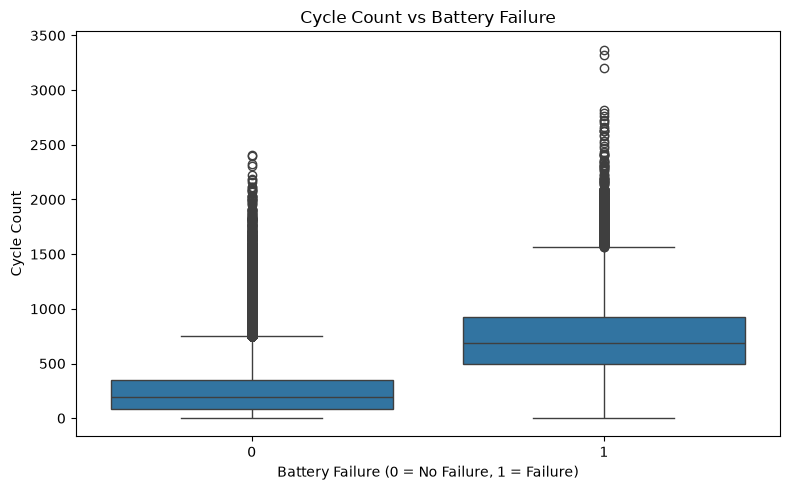

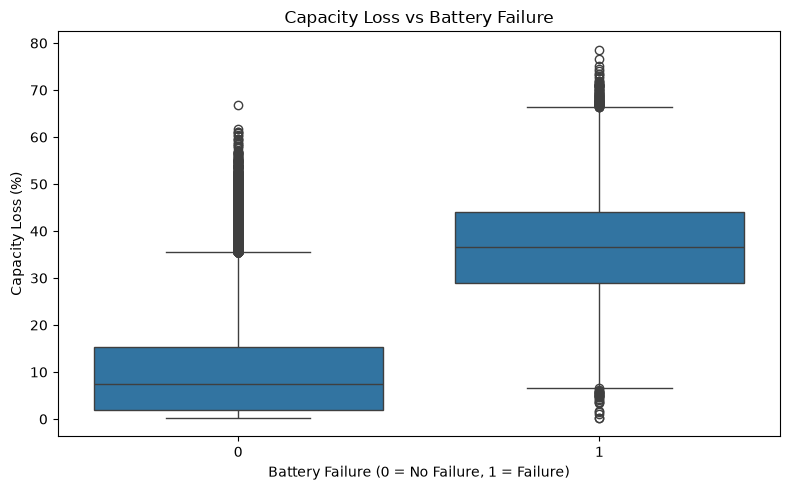

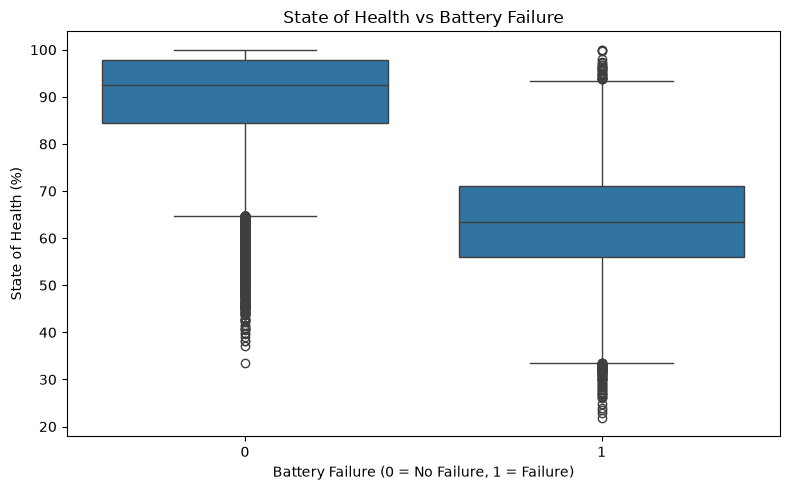

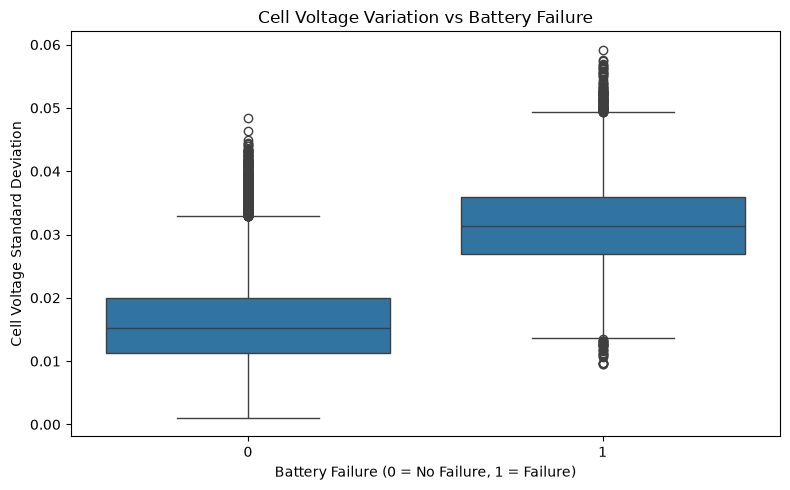

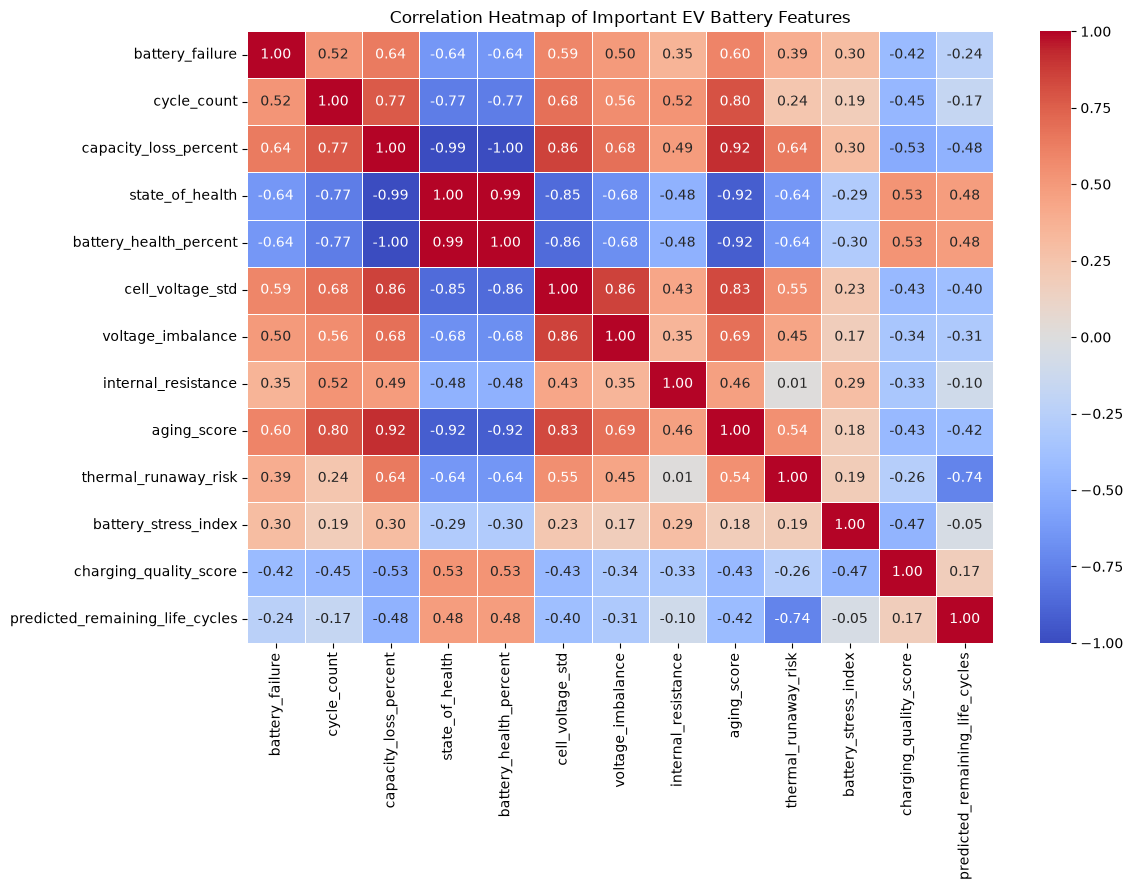

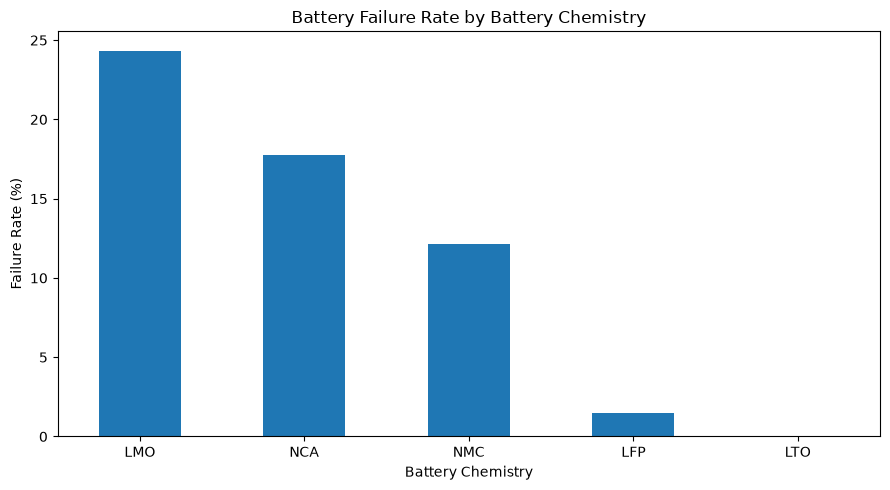

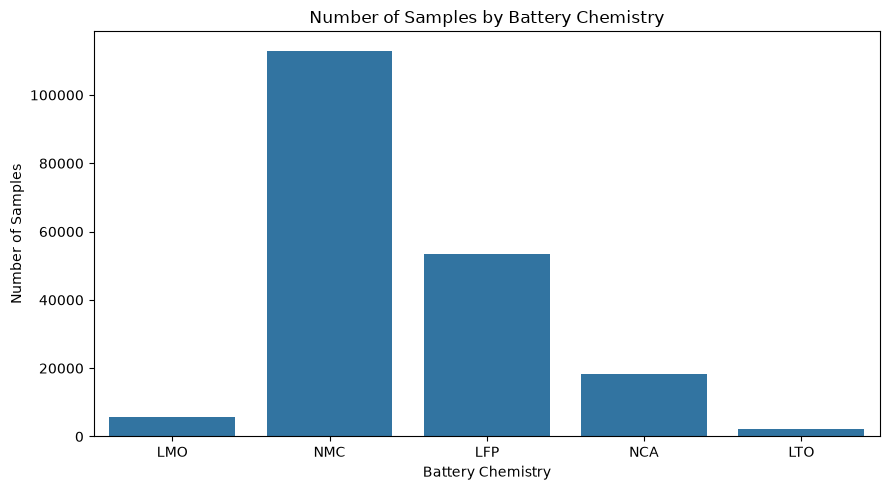

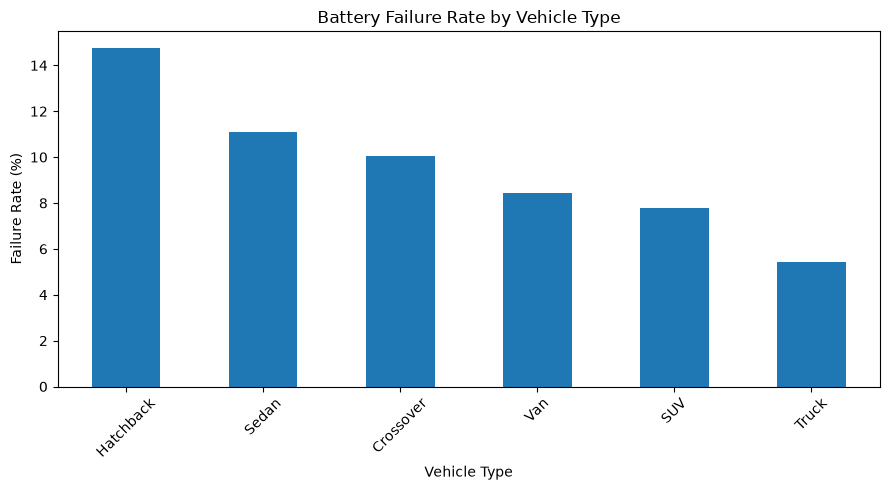

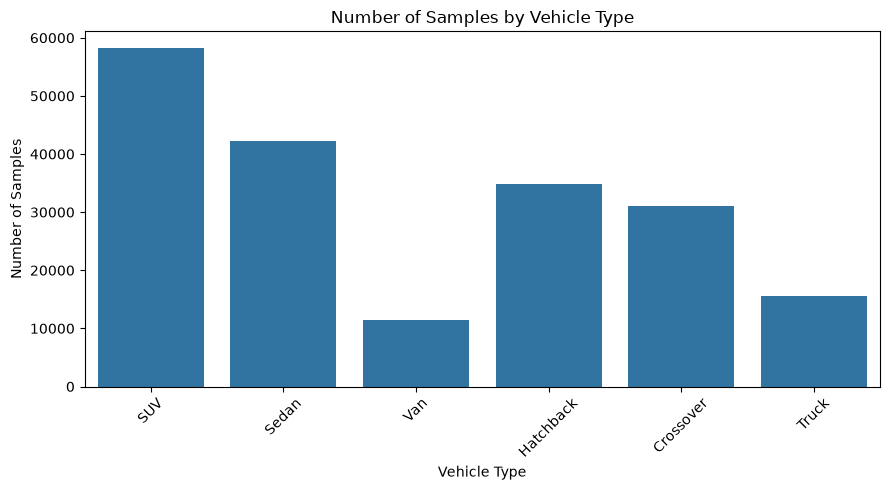

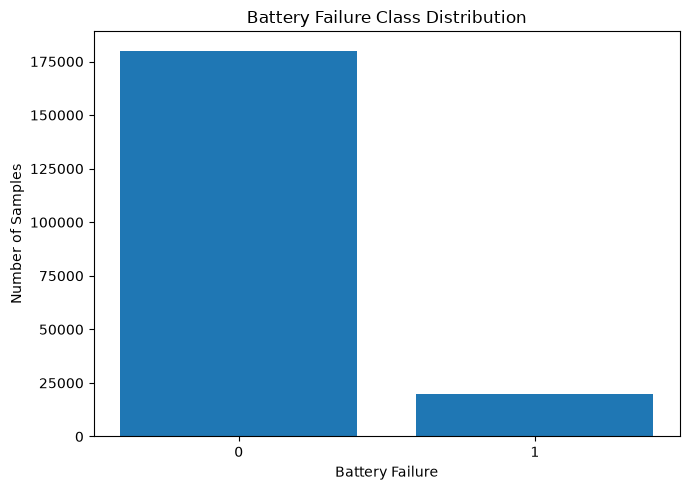

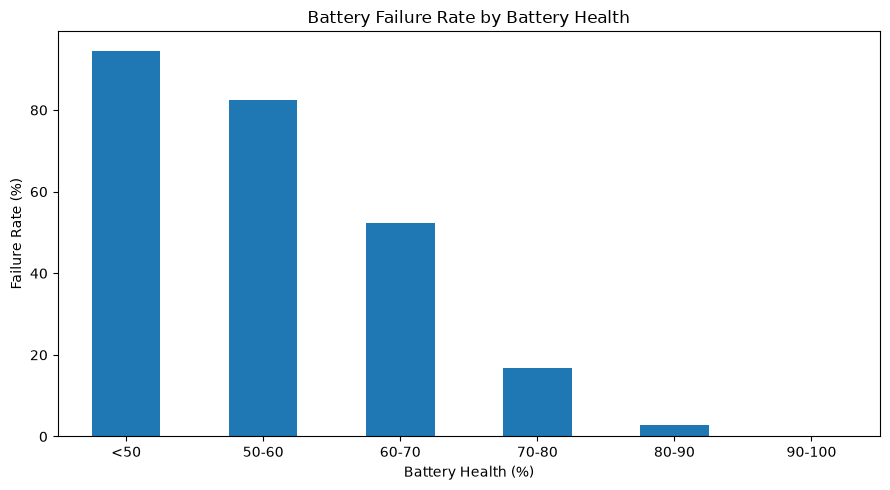

In [8]:
# 8. Visualizations
# --------------------------------------------------

def box_plot(col, title, y_label):
    if col in df.columns:
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df, x=target, y=col)
        plt.title(title)
        plt.xlabel("Battery Failure (0 = No Failure, 1 = Failure)")
        plt.ylabel(y_label)
        plt.tight_layout()
        plt.show()
    else:
        print(f"Skipping plot: '{col}' not found.")

box_plot("cycle_count", "Cycle Count vs Battery Failure", "Cycle Count")
box_plot("capacity_loss_percent", "Capacity Loss vs Battery Failure", "Capacity Loss (%)")
box_plot("state_of_health", "State of Health vs Battery Failure", "State of Health (%)")
box_plot("cell_voltage_std", "Cell Voltage Variation vs Battery Failure",
         "Cell Voltage Standard Deviation")

# Correlation heatmap
corr_cols = [
    target,
    "cycle_count",
    "capacity_loss_percent",
    "state_of_health",
    "battery_health_percent",
    "cell_voltage_std",
    "voltage_imbalance",
    "internal_resistance",
    "aging_score",
    "thermal_runaway_risk",
    "battery_stress_index",
    "charging_quality_score",
    "predicted_remaining_life_cycles"
]
corr_cols = [c for c in corr_cols if c in df.columns]

if len(corr_cols) > 1:
    corr = df[corr_cols].corr(numeric_only=True)
    plt.figure(figsize=(12, 9))
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5
    )
    plt.title("Correlation Heatmap of Important EV Battery Features")
    plt.tight_layout()
    plt.show()

# Failure rate by battery chemistry
if "battery_chemistry" in df.columns:
    chem_rate = (
        df.groupby("battery_chemistry")[target]
          .mean()
          .sort_values(ascending=False) * 100
    )

    plt.figure(figsize=(9, 5))
    chem_rate.plot(kind="bar")
    plt.title("Battery Failure Rate by Battery Chemistry")
    plt.xlabel("Battery Chemistry")
    plt.ylabel("Failure Rate (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9, 5))
    sns.countplot(data=df, x="battery_chemistry")
    plt.title("Number of Samples by Battery Chemistry")
    plt.xlabel("Battery Chemistry")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

# Failure rate and sample count by vehicle type
if "vehicle_type" in df.columns:
    veh_rate = (
        df.groupby("vehicle_type")[target]
          .mean()
          .sort_values(ascending=False) * 100
    )

    plt.figure(figsize=(9, 5))
    veh_rate.plot(kind="bar")
    plt.title("Battery Failure Rate by Vehicle Type")
    plt.xlabel("Vehicle Type")
    plt.ylabel("Failure Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9, 5))
    sns.countplot(data=df, x="vehicle_type")
    plt.title("Number of Samples by Vehicle Type")
    plt.xlabel("Vehicle Type")
    plt.ylabel("Number of Samples")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Target class distribution
plt.figure(figsize=(7, 5))
fail_counts = df[target].value_counts().sort_index()
plt.bar(fail_counts.index.astype(str), fail_counts.values)
plt.title("Battery Failure Class Distribution")
plt.xlabel("Battery Failure")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# Failure rate by battery health groups
if "battery_health_percent" in df.columns:
    health_bins = [0, 50, 60, 70, 80, 90, 100]
    health_labels = ["<50", "50-60", "60-70", "70-80", "80-90", "90-100"]

    df["health_group"] = pd.cut(
        df["battery_health_percent"],
        bins=health_bins,
        labels=health_labels,
        include_lowest=True
    )

    health_rate = (
        df.groupby("health_group", observed=False)[target].mean() * 100
    )

    plt.figure(figsize=(9, 5))
    health_rate.plot(kind="bar")
    plt.title("Battery Failure Rate by Battery Health")
    plt.xlabel("Battery Health (%)")
    plt.ylabel("Failure Rate (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

### Notes on the exploratory preprocessing section

- Numerical missing values are replaced with the training-set median, then standardized.
- Categorical missing values are replaced with `Unknown`; one-hot encoding ignores categories not seen during fitting.
- This first preprocessing output is for EDA and inspection only.
- The final modeling workflow creates its own validation split before fitting preprocessing.
- The experimental modeling section includes all available predictor columns except `vehicle_id` and `battery_serial`.
- Derived and EDA-generated features are intentionally retained for this experiment.

## Part 2 — Classification model training and evaluation

This section prepares the modeling data, compares three classifiers, selects a decision threshold on validation data, and evaluates the selected model on a held-out test set.

**Experimental configuration:**

1. All available dataset columns are included as predictors, except `vehicle_id` and `battery_serial`.
2. All original and derived features are retained.
3. The raw training partition is divided into model-training and validation subsets before fitting preprocessing.
4. Imputation, scaling, and encoding are fitted using model-training data only.
5. The test partition is held back until final evaluation.

**Experiment objective:** Measure how including all available features affects classification performance.

### 10. Import modeling and evaluation libraries

Load the estimators and classification metrics required for model comparison and final evaluation.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    precision_recall_curve
)

### 11. Separate predictors and target

Separate the target variable from the predictor columns.

For this experiment, retain every available dataset column as a predictor except the two identifier columns:

- `vehicle_id`
- `battery_serial`

All original, derived, and EDA-generated features are retained to experimentally evaluate their contribution to battery failure prediction.

In [10]:

# 1. Separate features and target

target = "battery_failure"

# Exclude only the two identifier columns
id_cols = [
    c for c in ["vehicle_id", "battery_serial"]
    if c in df.columns
]

# Retain every other available column as a predictor
X = df.drop(
    columns=[target] + id_cols
).copy()

y = df[target].copy()


# 2. Convert categorical dtypes to object
# This supports missing-value replacement with "Unknown",
# including EDA-generated categorical columns such as health_group.

cat_dtype_cols = X.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

X[cat_dtype_cols] = X[cat_dtype_cols].astype("object")


# 3. Validate target

if y.isna().any():
    raise ValueError(
        "The target contains missing values. Resolve these before modeling."
    )

if set(y.unique()) != {0, 1}:
    raise ValueError(
        "This modeling workflow expects a binary target encoded as 0 and 1. "
        f"Found: {sorted(y.unique().tolist())}"
    )


# 4. Display dataset information

print("=" * 70)
print("ALL-FEATURE EXPERIMENT: FEATURE SELECTION")
print("=" * 70)

print("\nIdentifier columns excluded:", id_cols)
print("Target column:", target)

print("Original dataset columns:", df.shape[1])
print("Predictor columns retained:", X.shape[1])

print("\nCategorical columns converted to object:", len(cat_dtype_cols))

print("\nTarget distribution:")

display(
    y.value_counts()
    .rename_axis("battery_failure")
    .to_frame("count")
)

display(
    (y.value_counts(normalize=True) * 100)
    .rename("percent")
    .to_frame()
)


# 5. Verify feature selection

expected_predictors = [
    c for c in df.columns
    if c not in [target] + id_cols
]

assert X.columns.tolist() == expected_predictors

assert target not in X.columns

assert not any(c in X.columns for c in id_cols)

print("\nFeature selection verification: PASSED")
print("All available predictor columns are retained.")
print("Only the target and two identifiers are excluded.")


# 6. Check repeated identifiers

for group_col in id_cols:

    repeated = df[group_col].duplicated().sum()

    print(f"\nRepeated values in {group_col}: {repeated:,}")

    if repeated:
        print(
            f"WARNING: {group_col} is not unique. "
            "Consider a group-aware split to prevent records "
            "from the same entity appearing in both training and testing."
        )


ALL-FEATURE EXPERIMENT: FEATURE SELECTION

Identifier columns excluded: ['vehicle_id', 'battery_serial']
Target column: battery_failure
Original dataset columns: 71
Predictor columns retained: 68

Categorical columns converted to object: 9

Target distribution:


,count
battery_failure,
0,180079
1,19921


,percent
battery_failure,
0,90.0395
1,9.9605



Feature selection verification: PASSED
All available predictor columns are retained.
Only the target and two identifiers are excluded.

Repeated values in vehicle_id: 0

Repeated values in battery_serial: 225


### 12. Split into training and test sets

Reserve 20% of the raw records for final testing. Stratification keeps the class distribution comparable across partitions. No preprocessing is fitted at this stage.

In [11]:
# 2. Train-test split (raw, unprocessed features)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Raw training set:", X_tr.shape)
print("Raw testing set:", X_te.shape)


Raw training set: (160000, 68)
Raw testing set: (40000, 68)


### 13. Detect numerical and categorical columns

Identify feature types from the raw training partition. These column lists will be used by the preprocessing transformer.

In [12]:
# 3. Identify columns from raw training data
num_cols = X_tr.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_tr.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))


Numerical features: 59
Categorical features: 9


### 14. Define numerical preprocessing

Impute missing numerical values with the median and standardize the resulting features.

In [13]:
# 4. Numerical preprocessing
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

### 15. Define categorical preprocessing

Fill missing categorical values with `Unknown` and one-hot encode categories. Unseen categories at transform time are ignored.

In [14]:
# 5. Categorical preprocessing
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

### 16. Combine preprocessing

Create a `ColumnTransformer` for the numerical and categorical pipelines. **Do not fit it yet**: the raw training partition must first be divided into model-training and validation subsets.

In [15]:
# 6. Combine preprocessing (define only; do not fit yet)
prep = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

print("Preprocessing transformer created.")
print("It will be fitted only after the raw validation split.")


Preprocessing transformer created.
It will be fitted only after the raw validation split.


### 17. Create a validation split, then fit preprocessing

Split the raw training partition before fitting any preprocessing step. Fit imputation, scaling, and encoding only on the model-training subset; transform validation data using those fitted transformations.

In [16]:
# 7. Validation split on RAW training features (prevents validation leakage)
X_a, X_v, y_a, y_v = train_test_split(
    X_tr, y_tr,
    test_size=0.20,
    random_state=42,
    stratify=y_tr
)

print("\nRaw model-training:", X_a.shape)
print("Raw validation:", X_v.shape)

# Fit preprocessing ONLY on the model-training subset.
X_a_p = prep.fit_transform(X_a)
X_v_p = prep.transform(X_v)

print("\nProcessed model-training:", X_a_p.shape)
print("Processed validation:", X_v_p.shape)

# Confirm that preprocessing output contains no NaN / infinity values.
def check_values(arr, name):
    vals = arr.data if hasattr(arr, "data") and not isinstance(arr, np.ndarray) else arr
    print(f"{name} NaN values:", np.isnan(vals).sum())
    print(f"{name} Infinite values:", np.isinf(vals).sum())

check_values(X_a_p, "Model-training")
check_values(X_v_p, "Validation")



Raw model-training: (128000, 68)
Raw validation: (32000, 68)

Processed model-training: (128000, 179)
Processed validation: (32000, 179)
Model-training NaN values: 0
Model-training Infinite values: 0
Validation NaN values: 0
Validation Infinite values: 0


### 18. Define candidate classifiers

Set up three classification algorithms:

1. Logistic Regression
2. Random Forest
3. Decision Tree

Class weights are used to account for possible class imbalance.

In [17]:
# 8. Define models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=42
    ),

    "Decision Trees": DecisionTreeClassifier(
        criterion='gini',
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42
    )
}

### 19. Train and evaluate candidate models

Fit each classifier on the processed model-training subset. Evaluate validation probabilities at the default 0.5 threshold, then select an F1-based threshold using validation data only.

In [18]:
# 9. Train and evaluate models
results = []
trained_models = {}
thresholds_dict = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_a_p, y_a)

    y_prob_val = model.predict_proba(X_v_p)[:, 1]
    y_pred_default = (y_prob_val >= 0.5).astype(int)

    # Metrics at the default 0.5 threshold
    acc = accuracy_score(y_v, y_pred_default)
    pre = precision_score(y_v, y_pred_default, zero_division=0)
    rec = recall_score(y_v, y_pred_default, zero_division=0)
    f1 = f1_score(y_v, y_pred_default, zero_division=0)
    roc = roc_auc_score(y_v, y_prob_val)
    pr = average_precision_score(y_v, y_prob_val)

    # Select the F1 threshold using validation data only.
    p, r, thresholds = precision_recall_curve(y_v, y_prob_val)

    if len(thresholds) == 0:
        best_th = 0.5
        best_val_f1 = f1
    else:
        f1_values = (
            2 * p[:-1] * r[:-1] /
            (p[:-1] + r[:-1] + 1e-10)
        )
        best_idx = int(np.argmax(f1_values))
        best_th = float(thresholds[best_idx])
        best_val_f1 = float(f1_values[best_idx])

    thresholds_dict[name] = best_th
    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": pre,
        "Recall": rec,
        "F1 Score": f1,
        "ROC-AUC": roc,
        "PR-AUC": pr,
        "Best Threshold": best_th,
        "Best Validation F1": best_val_f1
    })

    print(name, "completed.")



Training Logistic Regression...
Logistic Regression completed.

Training Random Forest...
Random Forest completed.

Training Decision Trees...
Decision Trees completed.


### 20. Compare model results

Collect the validation metrics and selected threshold into a single comparison table.

In [19]:
# 10. Model comparison
res = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(res.round(4))


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Best Threshold,Best Validation F1
0,Logistic Regression,0.9421,0.6394,0.9608,0.7678,0.9898,0.9240,0.8388,0.8369
1,Random Forest,0.9574,0.7995,0.7644,0.7815,0.9833,0.8762,0.4277,0.7876
2,Decision Trees,0.9271,0.5865,0.9081,0.7127,0.9261,0.8057,0.8659,0.7514


### 21. Plot model performance

Create a separate bar chart for each validation metric to make model differences easier to compare.

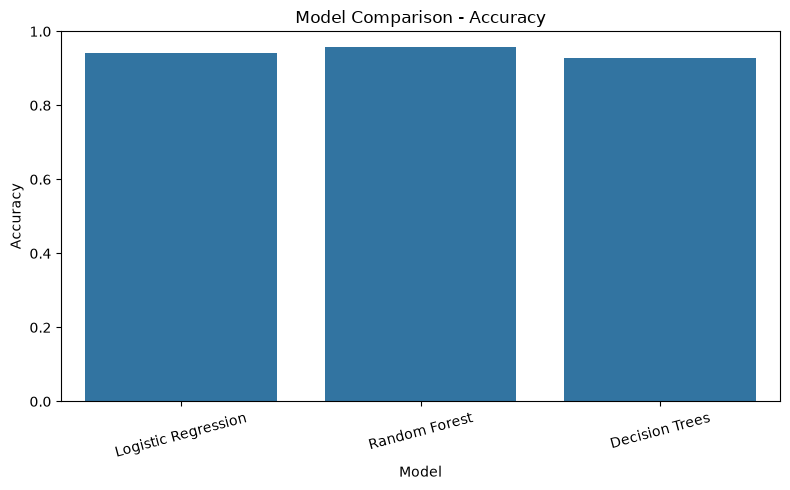

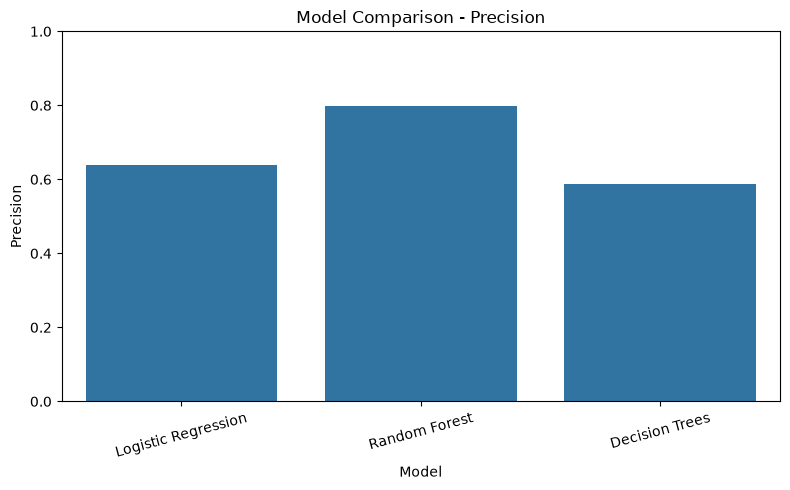

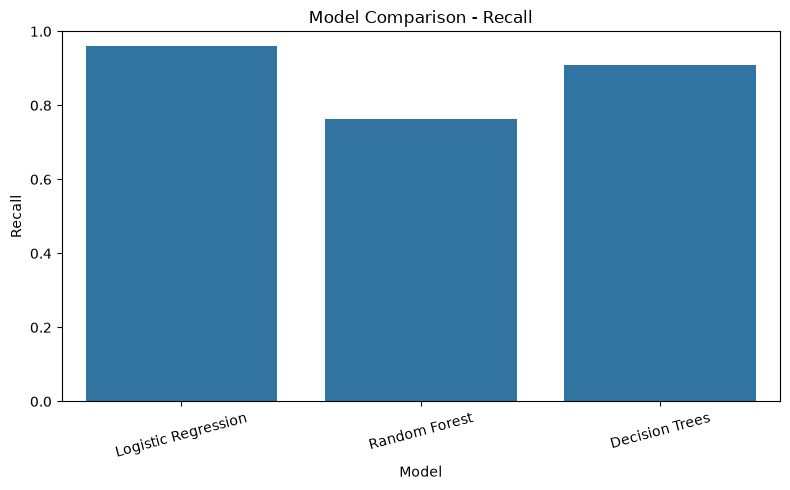

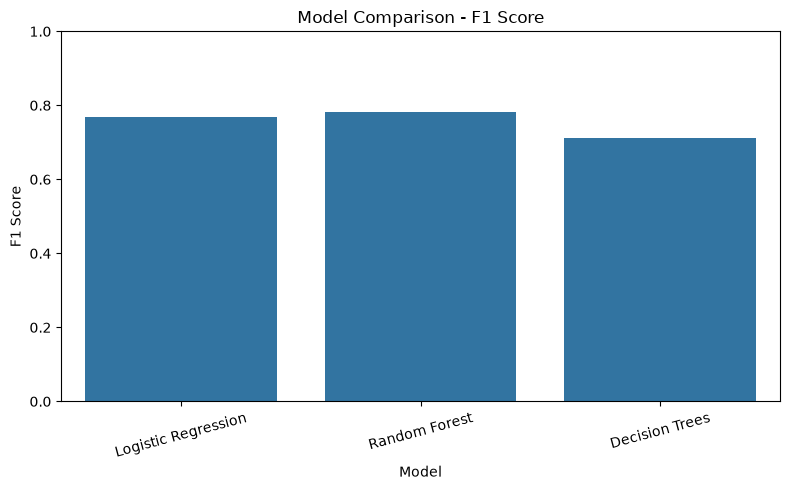

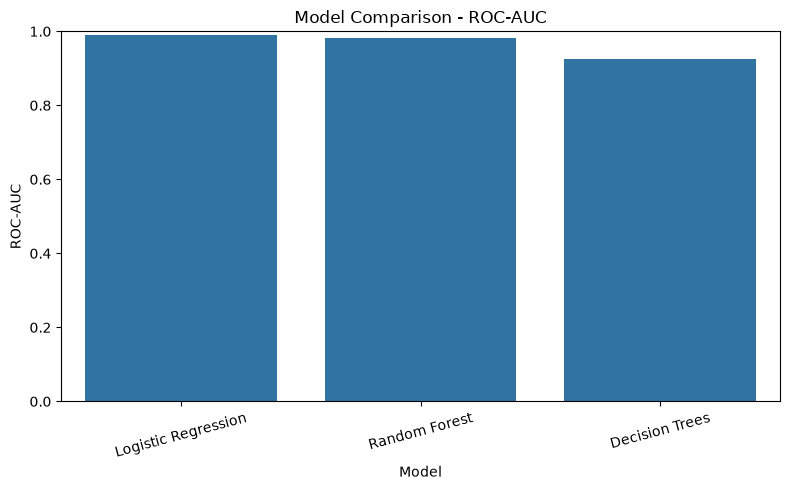

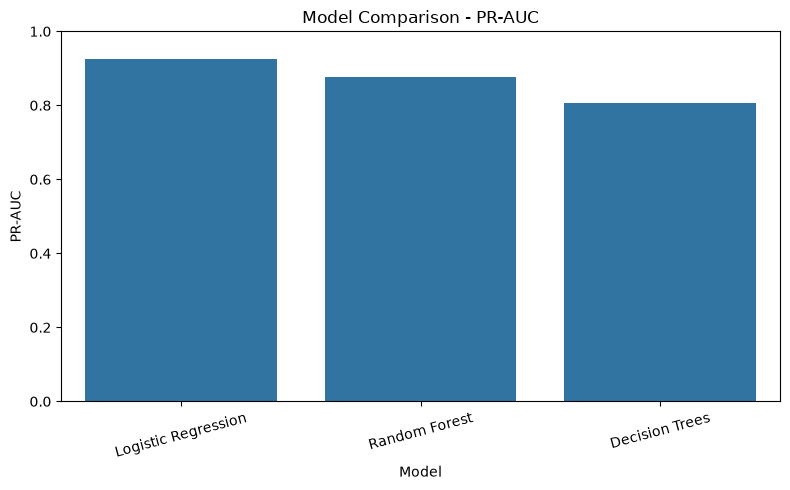

In [20]:
# 11. Visualize model performance
metrics = [
    'Accuracy', 'Precision', 'Recall',
    'F1 Score', 'ROC-AUC', 'PR-AUC'
]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=res,
        x='Model',
        y=metric
    )

    plt.title(f'Model Comparison - {metric}')
    plt.ylim(0, 1)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

### 22. Select the best model and threshold

Choose the candidate with the highest validation F1 and retrieve its corresponding validation-selected threshold. The test set is not used for this decision.

In [21]:
# 12. Select best model using validation F1
best_name = res.loc[
    res['Best Validation F1'].idxmax(),
    'Model'
]

best_th = thresholds_dict[best_name]
best_model = trained_models[best_name]

print("\nBest Model:", best_name)
print("Best Threshold:", round(best_th, 4))


Best Model: Logistic Regression
Best Threshold: 0.8388


### 23. Refit preprocessing and the selected model on all training data

After model and threshold selection are complete, refit the preprocessing transformer on the complete raw training partition, then refit the selected classifier on the transformed training partition. The held-out test data is only transformed, never used to fit preprocessing.

In [22]:
# 13. Refit preprocessing and best model on the complete training partition
X_tr_p = prep.fit_transform(X_tr)
X_te_p = prep.transform(X_te)

best_model.fit(X_tr_p, y_tr)

print("Final processed training shape:", X_tr_p.shape)
print("Final processed testing shape:", X_te_p.shape)
print("Preprocessing refitted on complete training data only.")


Final processed training shape: (160000, 179)
Final processed testing shape: (40000, 179)
Preprocessing refitted on complete training data only.


### 24. Predict on the test set

Generate failure probabilities for the held-out test records and convert them to class predictions using the threshold selected on validation data.

In [23]:
# 14. Final test predictions (one-time held-out evaluation)
y_prob = best_model.predict_proba(X_te_p)[:, 1]
y_pred = (y_prob >= best_th).astype(int)


### 25. Evaluate final test performance

Report the classification report, accuracy, precision, recall, F1, ROC-AUC, and average precision on the test set.

In [24]:
# 15. Final evaluation
print("\nFINAL TEST CLASSIFICATION REPORT\n")

print(classification_report(
    y_te,
    y_pred,
    target_names=['No Failure', 'Failure'],
    zero_division=0
))

print("Accuracy:", accuracy_score(y_te, y_pred))
print("Precision:", precision_score(y_te, y_pred, zero_division=0))
print("Recall:", recall_score(y_te, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_te, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_te, y_prob))
print("PR-AUC:", average_precision_score(y_te, y_prob))


FINAL TEST CLASSIFICATION REPORT

              precision    recall  f1-score   support

  No Failure       0.98      0.98      0.98     36016
     Failure       0.80      0.87      0.83      3984

    accuracy                           0.97     40000
   macro avg       0.89      0.92      0.91     40000
weighted avg       0.97      0.97      0.97     40000

Accuracy: 0.965375
Precision: 0.8024202932278334
Recall: 0.8654618473895582
F1 Score: 0.8327496679145031
ROC-AUC: 0.9893484491609262
PR-AUC: 0.922589474183096


### 26. Inspect the confusion matrix

Visualize true versus predicted classes to understand the types and counts of classification errors.

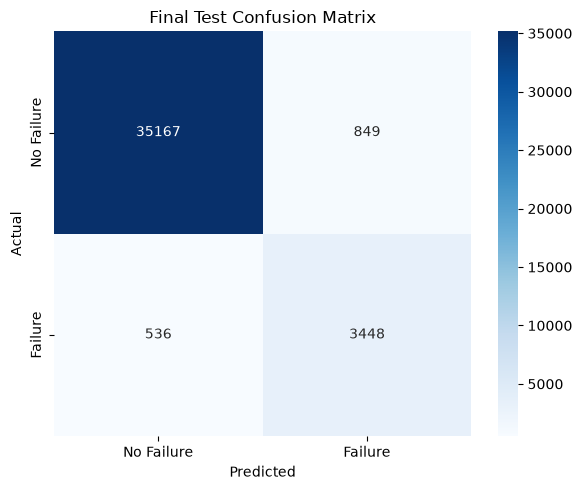

In [25]:
# 16. Confusion matrix
cm = confusion_matrix(y_te, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.title('Final Test Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## Interpretation and good-practice reminders

- **Recall:** Measures how many actual battery failures are detected.
- **Precision:** Measures how many predicted failures are actual failures.
- **F1:** Balances precision and recall.
- **ROC-AUC and PR-AUC:** Evaluate the ranking quality of predicted probabilities.
- The final test metrics estimate performance on unseen records under the chosen splitting strategy.
- This experiment deliberately includes all available predictor columns except the two identifiers.
- Some derived features may contain information that would not be available before an actual battery failure. Consequently, high performance must not automatically be interpreted as genuine predictive capability.
- If multiple rows belong to the same physical battery or vehicle, a group-aware split may be necessary.
- This experiment does not establish that the model is safe or suitable for deployment.